# Problem Statement

Agricultural activities are influenced by seasonal variations in environmental conditions, farming practices, resource availability and market conditions. As a result, agricultural performance may differ from one season to another. However, raw agricultural data does not clearly explain how agricultural performance changes across seasons or what patterns can be observed in different seasonal conditions. The problem is to analyze the given agricultural dataset and investigate seasonal differences in agricultural performance by identifying meaningful patterns, trends, relationships and variations within the available data.

## Importing Essential Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the Dataset

In [2]:
agri_df = pd.read_csv("seasonal_agriculture_performance_dataset.csv")

In [3]:
pd.set_option('display.max_columns', None)

In [4]:
agri_df

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Irrigation_Method,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,7.14,32.8,75.8,61.3,91.0,Drip,242.7,4.33,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,5.20,32.0,82.1,35.4,121.8,Flood,271.4,6.86,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,5.82,8.1,118.5,51.5,117.9,Drip,162.6,6.08,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,5.98,23.7,138.6,55.6,115.5,Rainfed,182.2,6.39,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,6.90,29.3,124.1,69.0,121.4,Flood,244.9,7.61,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,SF13996,Karnataka,Rajkot,Wheat,Kharif,4.72,865.4,27.3,51.4,6.3,7.97,27.3,104.3,44.8,94.0,Drip,271.1,5.45,0.74,0.51,2.41,22717,362917,54748,-308169,2016,1.195,45.2
3996,SF13997,Karnataka,Krishna,Chilli,Kharif,8.77,947.5,29.2,85.5,6.1,6.57,33.7,127.8,44.9,91.3,Drip,176.6,4.99,0.80,2.75,24.12,106459,496471,2567791,2071320,5351,4.508,59.7
3997,SF13998,Andhra Pradesh,Erode,Pulses,Zaid,10.47,80.0,35.4,68.5,8.6,7.25,21.1,126.7,59.9,148.0,Drip,234.7,6.27,0.99,0.62,6.49,66860,785632,433921,-351711,3392,1.913,29.2
3998,SF13999,Punjab,Warangal,Cotton,Kharif,1.73,475.0,28.2,61.7,6.4,6.11,30.5,107.5,20.7,91.0,Sprinkler,329.7,2.60,0.98,1.35,2.34,75282,153904,176160,22256,1220,1.918,50.4


In [5]:
# Using the info() to get info about the dataset
agri_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   object 
 1   State                          4000 non-null   object 
 2   District                       4000 non-null   object 
 3   Crop                           4000 non-null   object 
 4   Season                         4000 non-null   object 
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   f

In [6]:
# Using describe() function get statistics of Numeric columns
agri_df.describe()

,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
count,4000.000000,3952.000000,4000.00000,4000.000000,4000.000000,4000.000000,3960.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,3968.000000,4000.000000,4000.000000,4.000000e+03,4.000000e+03,4.000000e+03,4000.000000,4000.000000,4000.000000
mean,7.888265,601.152657,26.81890,63.210500,7.323050,6.701010,26.508232,120.250825,57.781850,104.760050,186.036000,5.070935,0.826138,5.270595,43.246210,44714.166250,5.263036e+05,6.378600e+05,1.115565e+05,6045.570250,5.385214,46.365875
std,4.223764,288.925025,3.81818,11.960834,1.121186,0.641461,6.712484,31.216452,17.015074,27.742681,60.260583,1.978879,0.101747,13.361398,126.880521,30266.161922,2.944191e+05,6.369747e+05,5.450819e+05,5572.944306,8.838101,12.424417
min,0.500000,80.000000,16.20000,25.000000,3.500000,5.200000,8.000000,40.000000,15.000000,30.000000,40.000000,0.500000,0.650000,0.300000,0.150000,2594.000000,2.682600e+04,6.107000e+03,-1.019223e+06,128.000000,0.135000,5.000000
25%,4.260000,370.200000,23.90000,54.775000,6.600000,6.260000,21.700000,98.500000,46.200000,86.200000,143.975000,3.690000,0.740000,1.050000,5.020000,21429.250000,2.745775e+05,2.075172e+05,-1.487318e+05,2268.750000,1.661000,37.300000
50%,7.895000,582.000000,26.90000,63.000000,7.300000,6.690000,26.400000,120.100000,57.500000,105.100000,186.250000,5.120000,0.830000,1.740000,11.770000,25913.000000,5.190825e+05,4.568305e+05,3.673000e+03,4435.000000,2.937500,46.400000
75%,11.650000,834.950000,29.60000,71.900000,8.100000,7.140000,31.300000,141.225000,69.400000,123.600000,227.200000,6.400000,0.910000,2.840000,24.355000,68279.000000,7.619965e+05,8.368748e+05,2.161878e+05,7829.750000,5.150250,54.900000
max,15.000000,1395.200000,39.70000,95.000000,11.000000,8.400000,47.000000,220.000000,120.000000,200.000000,400.000000,12.080000,1.000000,101.440000,1424.400000,131240.000000,1.349990e+06,5.080900e+06,4.345421e+06,40902.000000,79.800000,88.900000


## 1) Identifying and Classifying the variables in dataset

In [7]:
agri_df.columns.to_list()

['Farm_ID',
 'State',
 'District',
 'Crop',
 'Season',
 'Farm_Area_Hectares',
 'Rainfall_mm',
 'Avg_Temperature_C',
 'Humidity_pct',
 'Sunlight_Hours_Day',
 'Soil_pH',
 'Soil_Moisture_pct',
 'Nitrogen_kg_ha',
 'Phosphorus_kg_ha',
 'Potassium_kg_ha',
 'Irrigation_Method',
 'Fertilizer_kg_ha',
 'Pesticide_Litre_ha',
 'Seed_Quality_Score',
 'Yield_Tonnes_Ha',
 'Production_Tonnes',
 'Market_Price_INR_Tonne',
 'Total_Cost_INR',
 'Revenue_INR',
 'Profit_INR',
 'Water_Used_m3',
 'Water_Efficiency_t_per_1000m3',
 'Disease_Pest_Risk_pct']

The ___Season___ variable/column is our main focus around which entire anyalysis is going to revolve.

Now our main objective is analyse the __Agriculture Performance__, so to analyse the performance we can divide go with four performance metrics:

1) __Productivity__: _Yeild_Tonnes_Ha_, _Production_Tonnes_

2) __Economic Performance__: _Revenue_INR_, _Profit_INR_, _Total_Cost_INR_, _Market_Price_INR_Tonne_

3) __Resource Efficiency__: _Fertilizer_kg_ha_, _Pesticide_Litre_ha_, _Water_Used_m3_, _Water_Efficiency_t_per_1000m3_, _Farm_Area_Hectares_

4) __Risk__: _Disease_Pest_Risk_pct_



We can classify remaining columns/variables in following categorires which can't be used as performanc metrics but do affect __Agriculture Performance__:

1) __Grouping Variables__: _Farm_ID, State_, _District_, _Crop_, _Season_, _Irrigation_Method_

2) __Environmental Factors__: _Rainfall_mm_, _Avg_Temperature_C_, _Humidity_pct_, _Sunlight_Hours_Day_, _Soil_pH_, _Soil_Moisture_pct_

3) __Inputs__: _Nitrogen_kg_ha_, _Phosphorus_kg_ha_, _Potassium_kg_ha_, _Seed_Quality_Score_

## 2) Cleaning the Dataset

### 1. Finding filling the missing values

In [8]:
agri_df.isnull().sum().sort_values(ascending=False)

Rainfall_mm                      48
Soil_Moisture_pct                40
Yield_Tonnes_Ha                  32
Farm_ID                           0
Irrigation_Method                 0
Water_Efficiency_t_per_1000m3     0
Water_Used_m3                     0
Profit_INR                        0
Revenue_INR                       0
Total_Cost_INR                    0
Market_Price_INR_Tonne            0
Production_Tonnes                 0
Seed_Quality_Score                0
Pesticide_Litre_ha                0
Fertilizer_kg_ha                  0
Potassium_kg_ha                   0
State                             0
Phosphorus_kg_ha                  0
Nitrogen_kg_ha                    0
Soil_pH                           0
Sunlight_Hours_Day                0
Humidity_pct                      0
Avg_Temperature_C                 0
Farm_Area_Hectares                0
Season                            0
Crop                              0
District                          0
Disease_Pest_Risk_pct       

Now the variables that are missing values differ based on season, every season has different raifall, different soil moisture and different yeild.

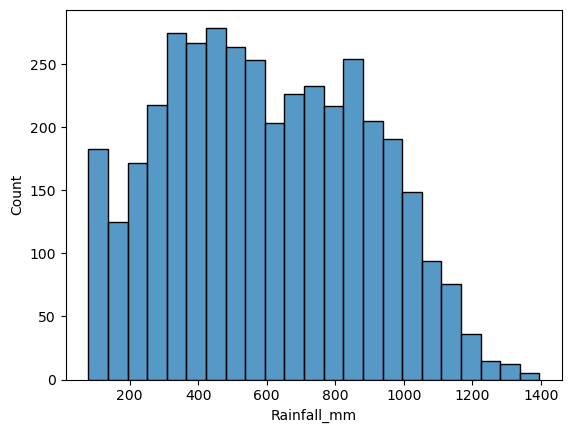

In [9]:
sns.histplot(agri_df['Rainfall_mm'])
plt.show()

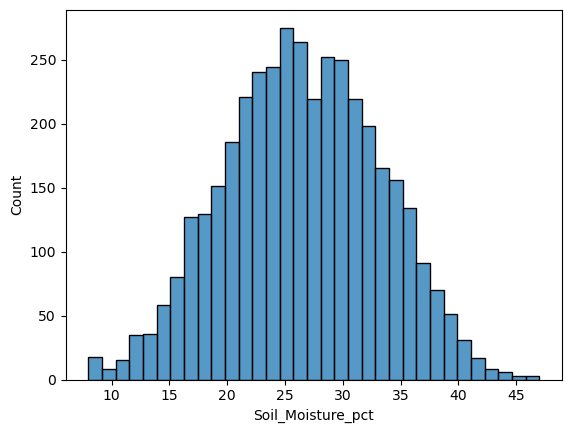

In [10]:
sns.histplot(agri_df['Soil_Moisture_pct'])
plt.show()

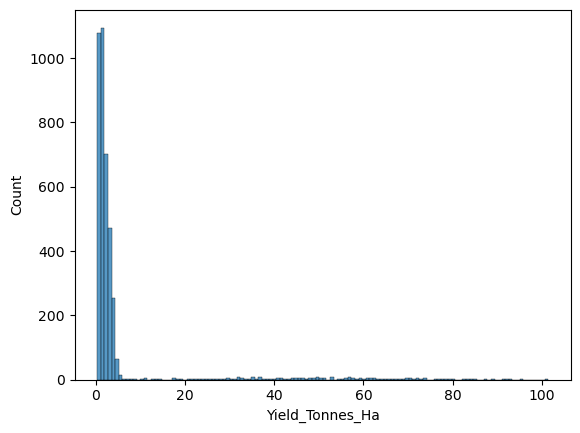

In [11]:
sns.histplot(agri_df['Yield_Tonnes_Ha'])
plt.show()

Using above histplots we can see how data is distributed:

1. Rainfall_mm — This is right-skewed.
2. Soil_Moisture_pct — This is symmetric.
3. Yield_Tonnes_Ha — This is heavily right-skewed

So we can use __mean__ to impute values in column ___Soil_Moisture_pct___ but it can't be used for other two columns as the data is not symmetrically distributed.

Mode is more suitable for categorical data hence it won't make sense here.

So it is more appropriate to impute the values using __Median__ here.

In [12]:
# Imputing values in Rainfall_mm column
agri_df['Rainfall_mm'] = agri_df['Rainfall_mm'].fillna(
    agri_df.groupby('Season')['Rainfall_mm'].transform('median')
)

In [13]:
# Imputing values in SOil_Moisture_pct column
agri_df['Soil_Moisture_pct'] = agri_df['Soil_Moisture_pct'].fillna(
    agri_df.groupby('Season')['Soil_Moisture_pct'].transform('median')
)

In [14]:
# Imputing values in Yield_Tonnes_Ha column
agri_df['Yield_Tonnes_Ha'] = agri_df['Yield_Tonnes_Ha'].fillna(
    agri_df.groupby('Season')['Yield_Tonnes_Ha'].transform('median')
)

In [15]:
agri_df.isnull().sum()

Farm_ID                          0
State                            0
District                         0
Crop                             0
Season                           0
Farm_Area_Hectares               0
Rainfall_mm                      0
Avg_Temperature_C                0
Humidity_pct                     0
Sunlight_Hours_Day               0
Soil_pH                          0
Soil_Moisture_pct                0
Nitrogen_kg_ha                   0
Phosphorus_kg_ha                 0
Potassium_kg_ha                  0
Irrigation_Method                0
Fertilizer_kg_ha                 0
Pesticide_Litre_ha               0
Seed_Quality_Score               0
Yield_Tonnes_Ha                  0
Production_Tonnes                0
Market_Price_INR_Tonne           0
Total_Cost_INR                   0
Revenue_INR                      0
Profit_INR                       0
Water_Used_m3                    0
Water_Efficiency_t_per_1000m3    0
Disease_Pest_Risk_pct            0
dtype: int64

### 2. Creating new columns to make analysis easy

In [16]:
''' 
The Water_Used_m3 column difine how mush water was used in meter cube, now this for entire farm 
which can range from 10s to 100s of hectares, so it would be easy if we have the factor water used
per 1 hectare of the land.
'''

agri_df['Water_Used_Per_Ha'] = agri_df['Water_Used_m3'] / agri_df['Farm_Area_Hectares']

### 3. Checking if the Datset contains right Economic data

In [17]:
# Checking Revenue - TotalCost match the Profit
agri_df['Calculated_Profit'] = agri_df['Revenue_INR'] - agri_df['Total_Cost_INR']
agri_df['Profit_Diff'] = agri_df['Calculated_Profit'] - agri_df['Profit_INR']
agri_df['Profit_Diff'].describe()

count    4000.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: Profit_Diff, dtype: float64

In [18]:
# Checking if Production x Price match Revenue
agri_df['Calculated_Revenue'] = agri_df['Production_Tonnes'] * agri_df['Market_Price_INR_Tonne']
agri_df['Revenue_Diff'] = agri_df['Calculated_Revenue'] - agri_df['Revenue_INR']
agri_df['Revenue_Diff'].describe()

count    4000.000000
mean       -0.001800
std         0.285864
min        -0.500000
25%        -0.242500
50%         0.000000
75%         0.240000
max         0.500000
Name: Revenue_Diff, dtype: float64

So our __Calculated Profit__ and __Profit__ matches exactly.

And __Calcualted_Revenue__ and __Revenue__ is also close to eachother.

## 3) Classifying our Columns into above defined Classes

In [19]:
# Grouping Columns
grouping_cols = ['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Irrigation_Method']

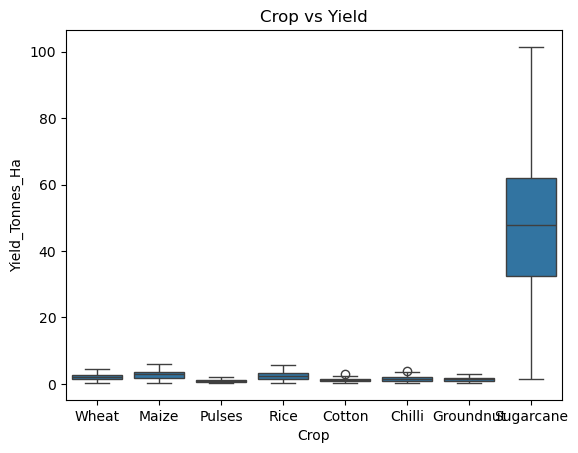

In [20]:
plt.title('Crop vs Yield')
sns.boxplot(data=agri_df, x='Crop', y='Yield_Tonnes_Ha')
plt.show()

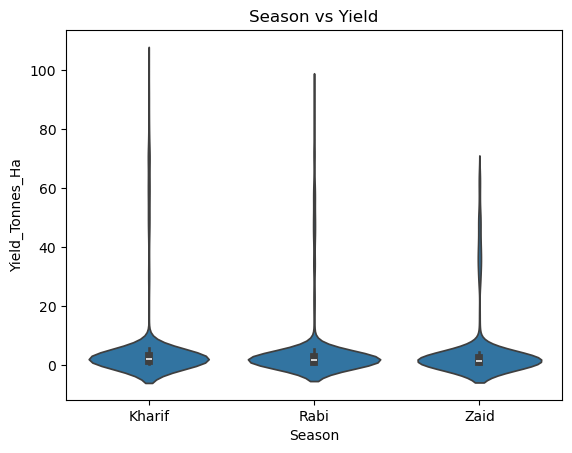

In [21]:
plt.title('Season vs Yield')
sns.violinplot(data=agri_df, x='Season', y='Yield_Tonnes_Ha')
plt.show()

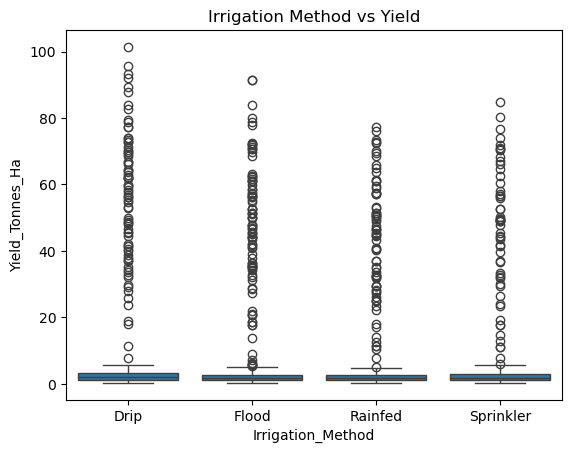

In [22]:
plt.title('Irrigation Method vs Yield')
sns.boxplot(data=agri_df, x='Irrigation_Method', y='Yield_Tonnes_Ha')
plt.show()

In [23]:
# Environmental factors
environmental_cols = ['Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct',
                       'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct']

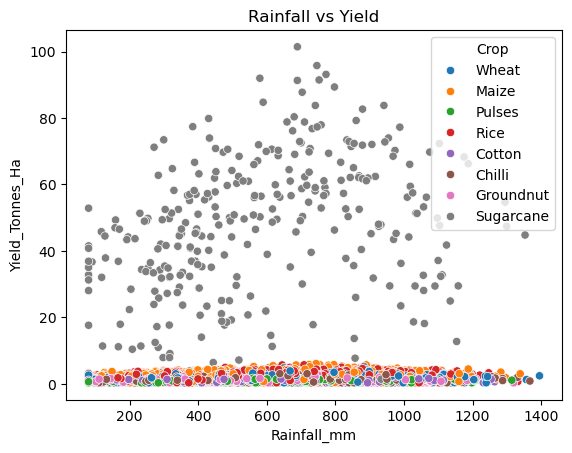

In [24]:
plt.title('Rainfall vs Yield')
sns.scatterplot(data=agri_df, x='Rainfall_mm', y='Yield_Tonnes_Ha', hue='Crop')
plt.show()

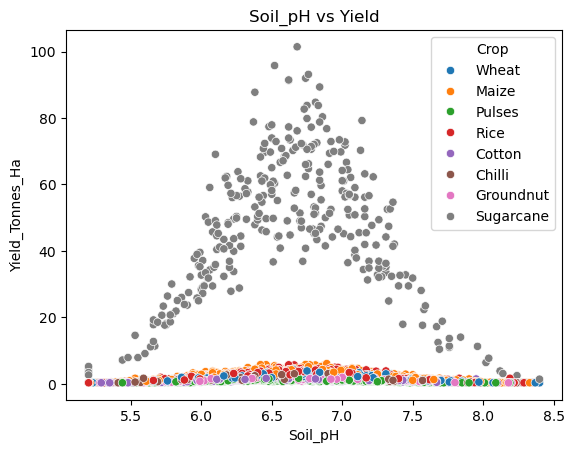

In [25]:
plt.title('Soil_pH vs Yield')
sns.scatterplot(data=agri_df, x='Soil_pH', y='Yield_Tonnes_Ha', hue='Crop')
plt.show()

In [26]:
# Input variables
input_cols = ['Nitrogen_kg_ha', 'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Seed_Quality_Score']

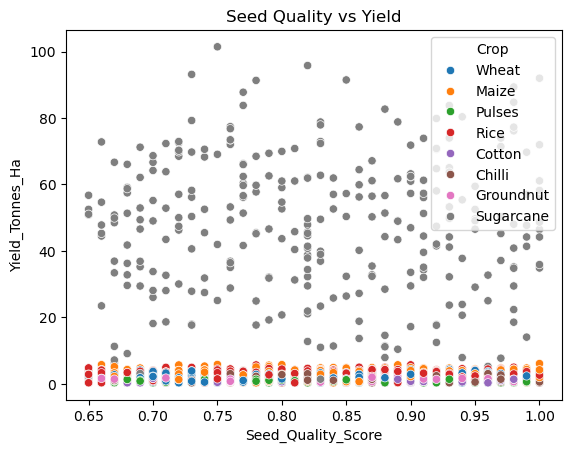

In [27]:
plt.title('Seed Quality vs Yield')
sns.scatterplot(data=agri_df, x='Seed_Quality_Score', y='Yield_Tonnes_Ha', hue='Crop')
plt.show()

In [28]:
# Productivity metrics
productivity_cols = ['Yield_Tonnes_Ha', 'Production_Tonnes']

In [29]:
# Economic performance metrics
economic_cols = ['Market_Price_INR_Tonne', 'Total_Cost_INR', 'Revenue_INR', 'Profit_INR']

In [30]:
# Resource efficiency metrics
resource_efficiency_cols = ['Water_Used_m3', 'Water_Efficiency_t_per_1000m3',
                             'Pesticide_Litre_ha', 'Farm_Area_Hectares', 'Fertilizer_kg_ha',
                               'Water_Used_Per_Ha']

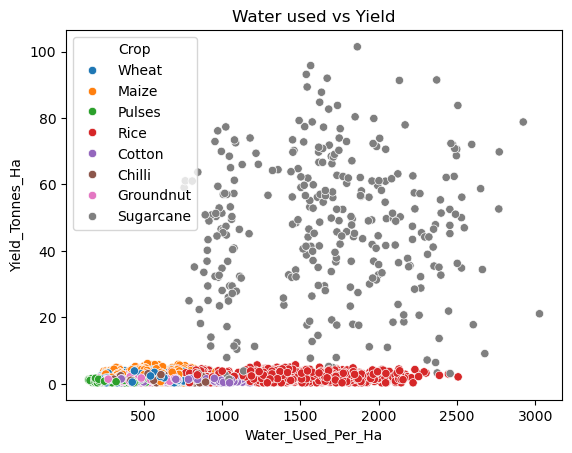

In [31]:
plt.title('Water used vs Yield')
sns.scatterplot(data=agri_df, x='Water_Used_Per_Ha', y='Yield_Tonnes_Ha', hue='Crop')
plt.show()

In [32]:
# Risk metrics
risk_cols = ['Disease_Pest_Risk_pct']

## 4) Getting Statistics of each Class by Season

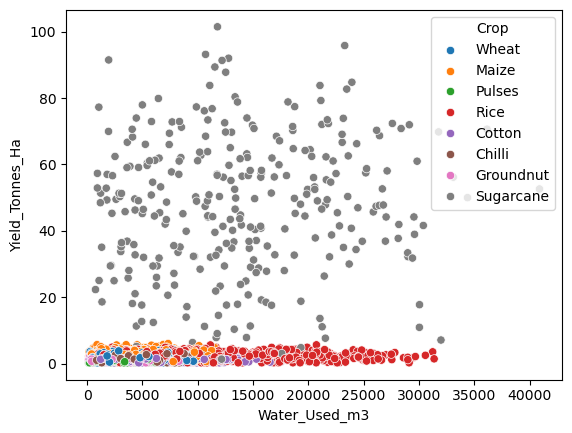

In [33]:
sns.scatterplot(data=agri_df, x='Water_Used_m3', y='Yield_Tonnes_Ha', hue='Crop')
plt.show()

Above scatterplot shows that ther is big differnce between yeild of __Sugarcane__ and other crops and hence sugarcane create a skew as other crops range from 0-10 or 15 at max sugarcane goes upto 100 which creates a significant gap between mean and median.

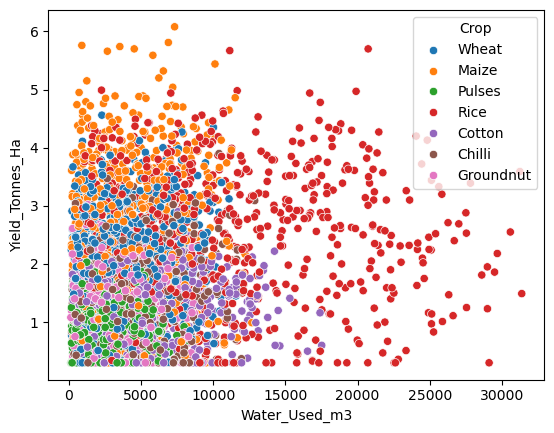

In [36]:
df_no_sugar = agri_df.where(agri_df['Crop'] != 'Sugarcane')
sns.scatterplot(data=df_no_sugar, x='Water_Used_m3', y='Yield_Tonnes_Ha', hue='Crop')
plt.show()

Now in above plot as e can see after removin sugarcane from the picture other crops yield at max upto 6 tonnes which makes a large differnce as sugarcen yield went upto 100 tonnes.

Now lets compare mean and median for every class with and without sugarcane.

### 1.Productivity Class

In [37]:
productivity_statistics = agri_df.groupby('Season')[productivity_cols]
productivity_statistics.describe()
'''
the 50% columns shows median
'''

'\nthe 50% columns shows median\n'

In [38]:
productivity_statistics = df_no_sugar.groupby('Season')[productivity_cols]
productivity_statistics.describe()

Yield_Tonnes_Ha                                                     \
                 count      mean       std  min     25%   50%   75%   max   
Season                                                                      
Kharif          1654.0  2.014740  1.168864  0.3  1.1200  1.82  2.81  6.08   
Rabi            1498.0  1.744866  1.018142  0.3  0.9725  1.55  2.41  5.44   
Zaid             543.0  1.465691  0.856949  0.3  0.8150  1.34  2.03  4.44   

       Production_Tonnes                                                      \
                   count       mean        std   min     25%    50%      75%   
Season                                                                         
Kharif            1654.0  16.099299  13.926099  0.20  4.9725  11.93  23.7425   
Rabi              1498.0  13.604753  12.042055  0.19  4.6300  10.09  19.1225   
Zaid               543.0  11.585101   9.568779  0.15  4.2400   8.87  16.7200   

               
          max  
Season         
Kharif  84.88  
Rabi    72.54  
Zaid    59.12

#### Ranking: Kharif > Rabi > Zaid
Incase of zaid is lowest yield season.

### 2.Economic Class

In [39]:
economic_statistics = agri_df.groupby('Season')[economic_cols]
economic_statistics.describe()

Market_Price_INR_Tonne                                                \
                        count          mean           std     min       25%   
Season                                                                        
Kharif                 1779.0  44850.906127  30301.557639  2772.0  21391.00   
Rabi                   1627.0  44747.974800  30309.563409  2594.0  21533.00   
Zaid                    594.0  44212.033670  30086.234044  2762.0  21351.25   

                                    Total_Cost_INR                 \
            50%       75%       max          count           mean   
Season                                                              
Kharif  25793.0  68195.00  131240.0         1779.0  531804.408094   
Rabi    26041.0  68398.50  131157.0         1627.0  513836.578365   
Zaid    25749.5  68067.75  128238.0          594.0  543976.728956   

                                                                          \
                  std      min        25%       50%       75%        max   
Season                                                                     
Kharif  298487.687038  30901.0  266922.00  524840.0  776733.0  1297725.0   
Rabi    288386.891838  27026.0  276659.50  506733.0  739141.5  1349990.0   
Zaid    297576.858682  26826.0  300043.25  534833.0  771336.0  1258745.0   

       Revenue_INR                                                             \
             count           mean            std     min        25%       50%   
Season                                                                          
Kharif      1779.0  710719.055649  708710.370061  8760.0  229612.00  520196.0   
Rabi        1627.0  601526.048556  584545.521423  6107.0  205093.50  438156.0   
Zaid         594.0  519171.904040  509524.546191  6709.0  181131.75  373700.5   

                            Profit_INR                                \
             75%        max      count           mean            std   
Season                                                                 
Kharif  930684.0  5080900.0     1779.0  178914.647555  611549.783883   
Rabi    798589.0  4350998.0     1627.0   87689.470191  489901.254255   
Zaid    664414.0  3502589.0      594.0  -24804.824916  436356.747261   

                                                            
              min       25%      50%        75%        max  
Season                                                      
Kharif  -976860.0 -108481.0  38808.0  285549.00  4345421.0  
Rabi   -1019223.0 -145342.5  -3187.0  183358.50  3378879.0  
Zaid    -965197.0 -254893.0 -62144.0   62730.25  2349990.0

In [40]:
economic_statistics = df_no_sugar.groupby('Season')[economic_cols]
economic_statistics.describe()

Market_Price_INR_Tonne                                                \
                        count          mean           std      min      25%   
Season                                                                        
Kharif                 1654.0  47977.769649  29126.857414  15000.0  22076.5   
Rabi                   1498.0  48301.185581  28956.556770  14462.0  22373.5   
Zaid                    543.0  48032.653775  28635.970728  15238.0  22235.0   

                                    Total_Cost_INR                 \
            50%       75%       max          count           mean   
Season                                                              
Kharif  27856.0  69574.25  131240.0         1654.0  529595.146917   
Rabi    46523.0  69365.00  131157.0         1498.0  511743.532043   
Zaid    43633.0  68831.00  128238.0          543.0  540443.000000   

                                                                          \
                  std      min       25%       50%        75%        max   
Season                                                                     
Kharif  298714.394396  30901.0  263936.5  523994.5  775000.00  1297725.0   
Rabi    289652.458385  27026.0  272721.0  504634.5  740403.25  1349990.0   
Zaid    295728.369640  26826.0  297593.5  527158.0  763371.00  1258745.0   

       Revenue_INR                                                             \
             count           mean            std     min        25%       50%   
Season                                                                          
Kharif      1654.0  646397.025393  630894.029513  8760.0  217297.25  486761.5   
Rabi        1498.0  543981.655541  502426.553690  6107.0  192632.75  407098.0   
Zaid         543.0  458491.817680  419557.043137  6709.0  170379.50  349716.0   

                            Profit_INR                                \
             75%        max      count           mean            std   
Season                                                                 
Kharif  877887.0  5080900.0     1654.0  116801.878476  537872.947133   
Rabi    731022.0  3987664.0     1498.0   32238.123498  412742.486628   
Zaid    626909.5  3029729.0      543.0  -81951.182320  363705.507233   

                                                            
              min       25%      50%        75%        max  
Season                                                      
Kharif  -976860.0 -123783.0  25057.0  228949.00  4345421.0  
Rabi   -1019223.0 -157972.0 -12768.5  124904.75  3159447.0  
Zaid    -965197.0 -263840.0 -86480.0   22479.50  2261661.0

#### Ranking: Kharif > Rabi > Zaid
Incase of Profit farmers are going into loss in Zaid season, though with sugarcane the avg profit is high though it in negatives but when sugarcane is removedd from the picture the profit redices by alot, farmers are putting more money in the season of Zaid and are at loss the highest in this season.

### 3. Resource Efficiency Class

In [41]:
resource_statistics = agri_df.groupby('Season')[resource_efficiency_cols]
resource_statistics.describe()

Water_Used_m3                                                   \
               count         mean          std    min     25%     50%   
Season                                                                  
Kharif        1779.0  6102.201237  5670.582696  139.0  2293.5  4469.0   
Rabi          1627.0  5846.987093  5397.648066  128.0  2192.5  4292.0   
Zaid           594.0  6419.893939  5734.619854  182.0  2539.5  4805.0   

                         Water_Efficiency_t_per_1000m3                      \
            75%      max                         count      mean       std   
Season                                                                       
Kharif  7774.50  36156.0                        1779.0  5.891834  9.833333   
Rabi    7696.00  40902.0                        1627.0  5.186122  8.258037   
Zaid    8155.25  34392.0                         594.0  4.413239  6.930111   

                                             Pesticide_Litre_ha            \
          min     25%     50%    75%     max              count      mean   
Season                                                                      
Kharif  0.135  1.8385  3.2770  5.512  79.800             1779.0  5.079747   
Rabi    0.146  1.6395  2.7400  5.040  75.340             1627.0  5.024690   
Zaid    0.140  1.2050  2.3015  4.147  48.545              594.0  5.171212   

                                                   Farm_Area_Hectares  \
             std  min     25%    50%    75%    max              count   
Season                                                                  
Kharif  1.959252  0.5  3.7400  5.180  6.400  11.80             1779.0   
Rabi    1.994465  0.5  3.6550  5.020  6.370  12.08             1627.0   
Zaid    1.993728  0.5  3.7525  5.185  6.525  11.78              594.0   

                                                               \
            mean       std  min     25%    50%     75%    max   
Season                                                          
Kharif  7.944924  4.282328  0.5  4.1100  8.180  11.825  15.00   
Rabi    7.752207  4.179402  0.5  4.2650  7.680  11.460  15.00   
Zaid    8.091246  4.162594  0.5  4.5625  8.085  11.595  14.99   

       Fertilizer_kg_ha                                                        \
                  count        mean        std   min      25%     50%     75%   
Season                                                                          
Kharif           1779.0  187.077965  60.819319  40.0  143.000  188.20  227.40   
Rabi             1627.0  185.407068  59.950613  40.0  144.950  185.30  228.75   
Zaid              594.0  184.638047  59.469455  40.0  145.275  183.95  220.55   

              Water_Used_Per_Ha                                      \
          max             count        mean         std         min   
Season                                                                
Kharif  381.3            1779.0  758.171355  496.086995  148.190476   
Rabi    400.0            1627.0  763.358257  523.434474  150.033535   
Zaid    400.0             594.0  792.581459  522.051242  171.669004   

                                                         
               25%         50%         75%          max  
Season                                                   
Kharif  422.938986  610.148233  873.222871  2770.357454  
Rabi    399.531388  595.454545  877.658023  3027.272727  
Zaid    431.208812  619.053078  919.602234  2662.650602

In [42]:
resource_statistics = df_no_sugar.groupby('Season')[resource_efficiency_cols]
resource_statistics.describe()

Water_Used_m3                                                    \
               count         mean          std    min      25%     50%   
Season                                                                   
Kharif        1654.0  5528.795042  4963.929291  139.0  2173.25  4285.0   
Rabi          1498.0  5165.805741  4511.071432  128.0  2092.25  3992.0   
Zaid           543.0  5636.237569  4750.719535  182.0  2428.50  4516.0   

                         Water_Efficiency_t_per_1000m3                      \
            75%      max                         count      mean       std   
Season                                                                       
Kharif  7213.75  31242.0                        1654.0  3.616132  2.510910   
Rabi    6856.00  31373.0                        1498.0  3.228004  2.340098   
Zaid    7399.50  30583.0                         543.0  2.630818  1.955883   

                                               Pesticide_Litre_ha            \
          min      25%    50%      75%     max              count      mean   
Season                                                                        
Kharif  0.135  1.77325  3.079  4.84425  15.271             1654.0  5.077848   
Rabi    0.146  1.57475  2.572  4.40475  15.351             1498.0  5.023818   
Zaid    0.140  1.11200  2.113  3.49600  10.541              543.0  5.195249   

                                                  Farm_Area_Hectares  \
             std  min     25%    50%   75%    max              count   
Season                                                                 
Kharif  1.960067  0.5  3.7325  5.170  6.40  11.80             1654.0   
Rabi    1.992255  0.5  3.6400  5.015  6.38  11.23             1498.0   
Zaid    2.001107  0.5  3.7750  5.220  6.54  11.78              543.0   

                                                             Fertilizer_kg_ha  \
            mean       std  min    25%    50%     75%    max            count   
Season                                                                          
Kharif  7.910502  4.291652  0.5  4.050  8.165  11.810  15.00           1654.0   
Rabi    7.722276  4.195406  0.5  4.240  7.610  11.470  15.00           1498.0   
Zaid    8.040258  4.117873  0.5  4.515  7.990  11.525  14.96            543.0   

                                                                     \
              mean        std   min      25%    50%      75%    max   
Season                                                                
Kharif  187.491294  61.057533  40.0  143.000  188.3  229.275  381.3   
Rabi    185.192991  60.398088  40.0  144.525  184.4  228.950  400.0   
Zaid    184.908287  60.667521  40.0  145.350  184.8  221.650  400.0   

       Water_Used_Per_Ha                                                  \
                   count        mean         std         min         25%   
Season                                                                     
Kharif            1654.0  693.287422  429.347862  148.190476  405.535221   
Rabi              1498.0  681.827832  435.674949  150.033535  377.997798   
Zaid               543.0  702.105033  430.631550  171.669004  417.356552   

                                             
               50%         75%          max  
Season                                       
Kharif  580.439934  802.225636  2445.762712  
Rabi    565.019950  789.512712  2507.692308  
Zaid    586.029412  809.515187  2209.128065

#### Ranking: Kharif > Rabi > Zaid
Here Kharif is most water efficient season and Zaid is most water cinsumig season.

### 4. Risk Class

In [43]:
risk_statistics = agri_df.groupby('Season')[risk_cols]
risk_statistics.describe()

Disease_Pest_Risk_pct                                            \
                       count       mean        std   min     25%   50%   
Season                                                                   
Kharif                1779.0  54.467903  10.087931  21.3  47.500  54.5   
Rabi                  1627.0  40.482114  10.104157   5.1  33.450  40.6   
Zaid                   594.0  38.216667   9.873938   5.0  31.825  37.9   

                      
           75%   max  
Season                
Kharif  61.500  88.9  
Rabi    47.600  71.2  
Zaid    45.075  71.6

In [44]:
risk_statistics = df_no_sugar.groupby('Season')[risk_cols]
risk_statistics.describe()

Disease_Pest_Risk_pct                                                   \
                       count       mean        std   min    25%    50%    75%   
Season                                                                          
Kharif                1654.0  54.502056  10.049476  21.3  47.50  54.55  61.50   
Rabi                  1498.0  40.536916  10.100239   5.1  33.50  40.75  47.60   
Zaid                   543.0  38.203683   9.858508   5.0  31.85  37.90  45.05   

              
         max  
Season        
Kharif  87.7  
Rabi    71.2  
Zaid    71.6

#### Ranking: Kharif > Rabi > Zaid
Here Kharif has most Pest risk and Zaid being the lowest.

### 5. Input Class

In [45]:
input_statistics = agri_df.groupby('Season')[input_cols]
input_statistics.describe()

Nitrogen_kg_ha                                                      \
                count        mean        std   min    25%     50%     75%   
Season                                                                      
Kharif         1779.0  120.020124  31.176322  40.0  98.10  119.80  141.30   
Rabi           1627.0  120.402827  31.098788  40.0  99.10  120.30  140.55   
Zaid            594.0  120.525421  31.702789  40.0  98.65  120.15  143.50   

              Phosphorus_kg_ha                                             \
          max            count       mean        std   min     25%    50%   
Season                                                                      
Kharif  220.0           1779.0  58.096515  17.154119  15.0  46.000  57.40   
Rabi    220.0           1627.0  57.311002  17.119842  15.0  45.750  57.70   
Zaid    220.0            594.0  58.129125  16.291470  15.0  47.675  57.45   

                      Potassium_kg_ha                                       \
           75%    max           count        mean        std   min     25%   
Season                                                                       
Kharif  69.600  120.0          1779.0  105.303485  27.033286  30.0  87.050   
Rabi    69.200  120.0          1627.0  103.926060  28.868968  30.0  84.250   
Zaid    69.475  112.2           594.0  105.416835  26.658984  32.6  87.325   

                              Seed_Quality_Score                            \
          50%      75%    max              count      mean       std   min   
Season                                                                       
Kharif  104.8  123.700  184.0             1779.0  0.821613  0.101423  0.65   
Rabi    104.8  123.150  200.0             1627.0  0.832170  0.101561  0.65   
Zaid    106.3  124.275  176.7              594.0  0.823165  0.102560  0.65   

                               
         25%   50%   75%  max  
Season                         
Kharif  0.73  0.82  0.91  1.0  
Rabi    0.74  0.84  0.92  1.0  
Zaid    0.73  0.83  0.91  1.0

### 6. Enviromental Class

In [46]:
environmental_statistics = agri_df.groupby('Season')[environmental_cols]
environmental_statistics.describe()

Rainfall_mm                                                           \
             count        mean         std    min      25%     50%      75%   
Season                                                                        
Kharif      1779.0  852.112676  181.574933  160.5  727.800  854.75  976.850   
Rabi        1627.0  435.937062  174.685690   80.0  316.100  430.30  551.050   
Zaid         594.0  299.123232  152.561132   80.0  177.675  283.30  410.475   

               Avg_Temperature_C                                               \
           max             count       mean       std   min   25%   50%   75%   
Season                                                                          
Kharif  1395.2            1779.0  28.454019  2.510166  19.4  26.8  28.5  30.1   
Rabi    1146.5            1627.0  23.489183  2.459561  16.2  21.8  23.5  25.2   
Zaid     708.3             594.0  31.042088  2.554911  24.5  29.2  31.0  32.8   

             Humidity_pct                                                    \
         max        count       mean       std   min     25%    50%     75%   
Season                                                                        
Kharif  36.8       1779.0  71.812591  8.861902  36.9  65.900  71.90  77.800   
Rabi    31.1       1627.0  57.893178  9.001575  25.0  51.900  58.10  63.600   
Zaid    39.7        594.0  52.012121  9.051898  25.0  45.825  52.35  58.575   

             Sunlight_Hours_Day                                                \
         max              count      mean       std  min  25%  50%  75%   max   
Season                                                                          
Kharif  95.0             1779.0  6.793367  0.977077  3.5  6.1  6.8  7.5  10.3   
Rabi    86.3             1627.0  7.589797  1.001779  4.1  6.9  7.6  8.2  11.0   
Zaid    79.5              594.0  8.178788  1.045260  4.7  7.5  8.2  8.9  11.0   

       Soil_pH                                                     \
         count      mean       std  min   25%    50%     75%  max   
Season                                                              
Kharif  1779.0  6.727993  0.642986  5.2  6.29  6.730  7.1700  8.4   
Rabi    1627.0  6.673749  0.638481  5.2  6.22  6.670  7.1100  8.4   
Zaid     594.0  6.694865  0.642794  5.2  6.27  6.655  7.1175  8.4   

       Soil_Moisture_pct                                                      
                   count       mean       std   min    25%   50%   75%   max  
Season                                                                        
Kharif            1779.0  31.198426  5.017734  12.7  27.75  31.2  34.7  47.0  
Rabi              1627.0  24.050215  4.936114   8.0  20.70  24.0  27.3  39.9  
Zaid               594.0  19.169024  4.860799   8.0  15.90  19.1  22.4  33.6

This is the most import class that tells how crop yield changes season by season which is due to enviromental factors __Kharif__ having highest rainfall gives highest yield while __Zaid__ having lowest rainfall and harsh conditions gives lowest yield.

## 5) Visualizing Relation between Input-Environmental and Perfomance classes

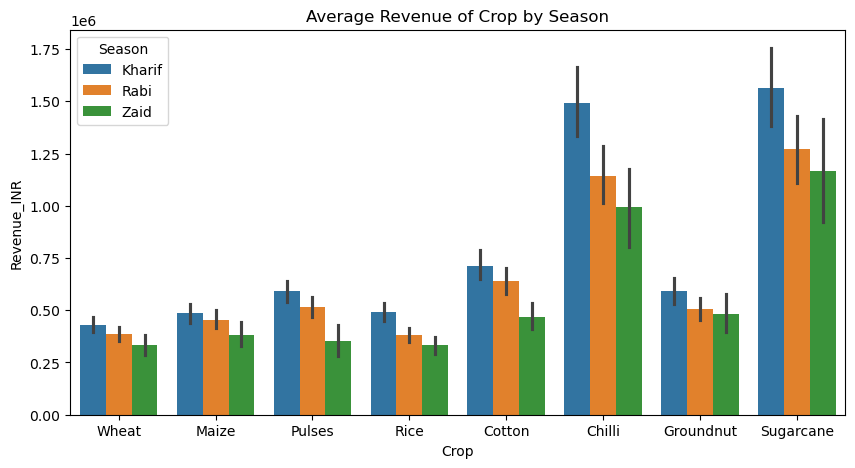

In [61]:
plt.figure(figsize=(10, 5))
plt.title('Average Revenue of Crop by Season')
sns.barplot(data=agri_df, x='Crop', y='Revenue_INR', hue='Season')
plt.show()

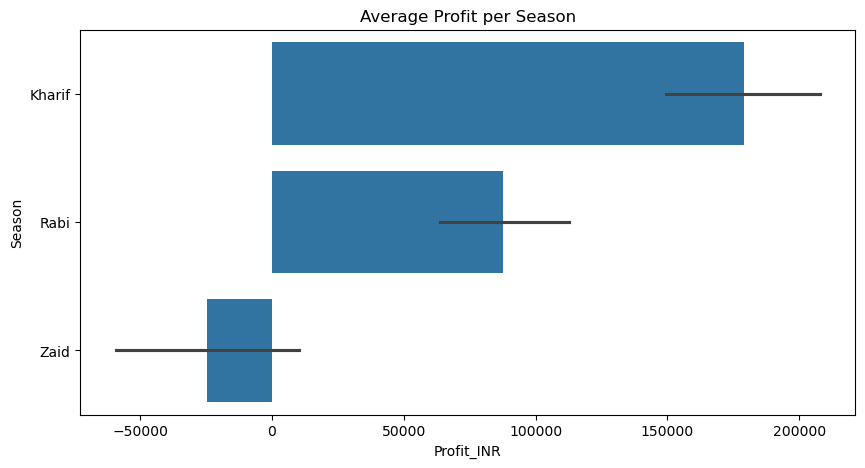

In [63]:
plt.figure(figsize=(10, 5))
plt.title('Average Profit per Season')
sns.barplot(data=agri_df, x='Profit_INR', y='Season')
plt.show()

In [47]:
# Creating input and output list using our predefined lists for building correlation matrix.
input_classes = environmental_cols + input_cols
output_classes = productivity_cols + economic_cols + resource_efficiency_cols + risk_cols

In [48]:
# Building the correlation matrix
corr_matrix = agri_df[input_classes + output_classes].corr()

In [49]:
corr_matrix

,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Pesticide_Litre_ha,Farm_Area_Hectares,Fertilizer_kg_ha,Water_Used_Per_Ha,Disease_Pest_Risk_pct
Rainfall_mm,1.000000,0.198595,0.526122,-0.366988,0.016413,0.520132,0.005237,0.020930,0.030724,-0.018887,0.028836,0.023145,0.000102,0.014783,0.097641,0.106117,0.003342,0.056698,0.001466,0.009124,0.024593,-0.013563,0.624405
Avg_Temperature_C,0.198595,1.000000,0.138136,-0.033863,0.029988,0.083264,0.018707,0.008508,0.022993,-0.031943,0.010026,0.007346,0.002951,0.041030,0.026703,0.009043,0.022995,0.006534,0.006657,0.036870,0.015861,-0.004854,0.245613
Humidity_pct,0.526122,0.138136,1.000000,-0.297298,0.028447,0.450693,0.001198,-0.005963,-0.003070,-0.045598,0.012337,0.003614,0.000262,0.006023,0.057358,0.063775,-0.002086,0.026169,-0.004028,0.000471,0.024623,-0.005865,0.545093
Sunlight_Hours_Day,-0.366988,-0.033863,-0.297298,1.000000,-0.017806,-0.304918,0.009920,0.001544,-0.014407,0.021257,-0.015362,-0.023504,-0.000696,-0.000655,-0.047216,-0.054822,-0.005717,-0.021386,-0.017238,0.001821,-0.013073,-0.001464,-0.253251
Soil_pH,0.016413,0.029988,0.028447,-0.017806,1.000000,0.030905,0.006286,0.016620,-0.019407,-0.004181,-0.020691,-0.012512,0.022226,0.005302,-0.008798,-0.013145,-0.022859,-0.010087,-0.010135,0.009857,-0.010591,-0.052955,0.031141
Soil_Moisture_pct,0.520132,0.083264,0.450693,-0.304918,0.030905,1.000000,0.007505,0.014346,0.007933,-0.020572,0.011101,0.005321,0.016078,0.002521,0.080266,0.092436,0.004687,0.028061,-0.022712,0.004187,0.007427,-0.010757,0.378607
Nitrogen_kg_ha,0.005237,0.018707,0.001198,0.009920,0.006286,0.007505,1.000000,0.010199,0.010490,0.014896,0.053167,0.048182,-0.022595,0.011900,0.078252,0.085016,0.022127,0.054896,0.014280,0.013658,-0.032440,0.015972,-0.011503
Phosphorus_kg_ha,0.020930,0.008508,-0.005963,0.001544,0.016620,0.014346,0.010199,1.000000,0.002847,-0.007575,0.047974,0.034957,-0.005174,-0.016508,0.034940,0.049747,-0.000752,0.057129,-0.029942,-0.006625,0.012905,0.013137,0.032061
Potassium_kg_ha,0.030724,0.022993,-0.003070,-0.014407,-0.019407,0.007933,0.010490,0.002847,1.000000,0.006862,0.003363,0.004472,0.007572,0.003431,0.028278,0.031192,0.001667,0.006575,-0.004675,0.000195,0.017254,0.002643,0.013403
Seed_Quality_Score,-0.018887,-0.031943,-0.045598,0.021257,-0.004181,-0.020572,0.014896,-0.007575,0.006862,1.000000,-0.007231,-0.000387,0.011960,0.022033,0.019116,0.010438,0.017020,-0.012031,-0.001462,0.015236,0.016144,0.016908,-0.024602


### HeatMap for all Seasons Combined

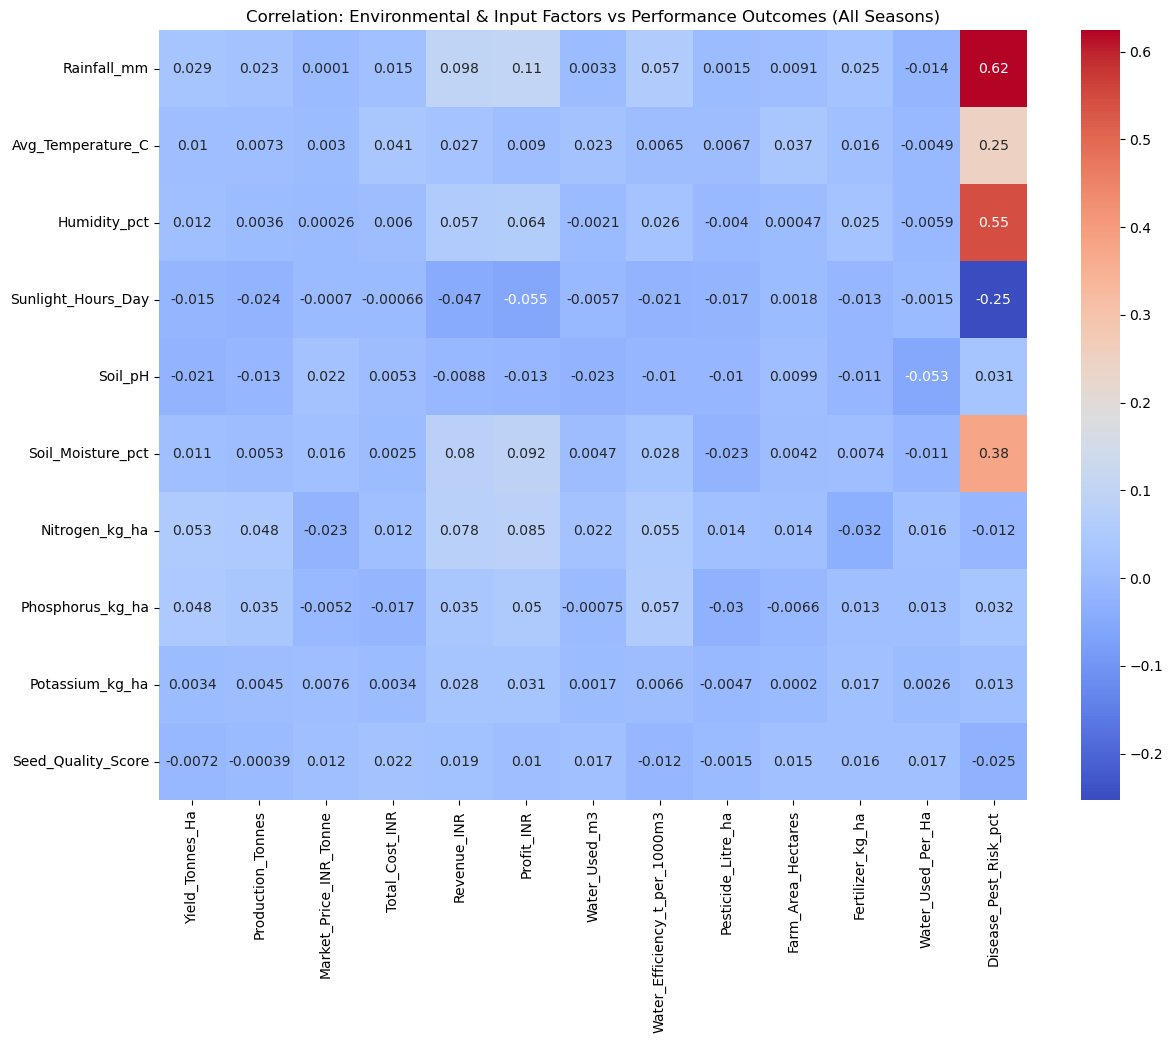

In [50]:
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix.loc[input_classes, output_classes], annot=True, cmap='coolwarm')
plt.title('Correlation: Environmental & Input Factors vs Performance Outcomes (All Seasons)')
plt.show()

### 2. HeatMap for Kharif


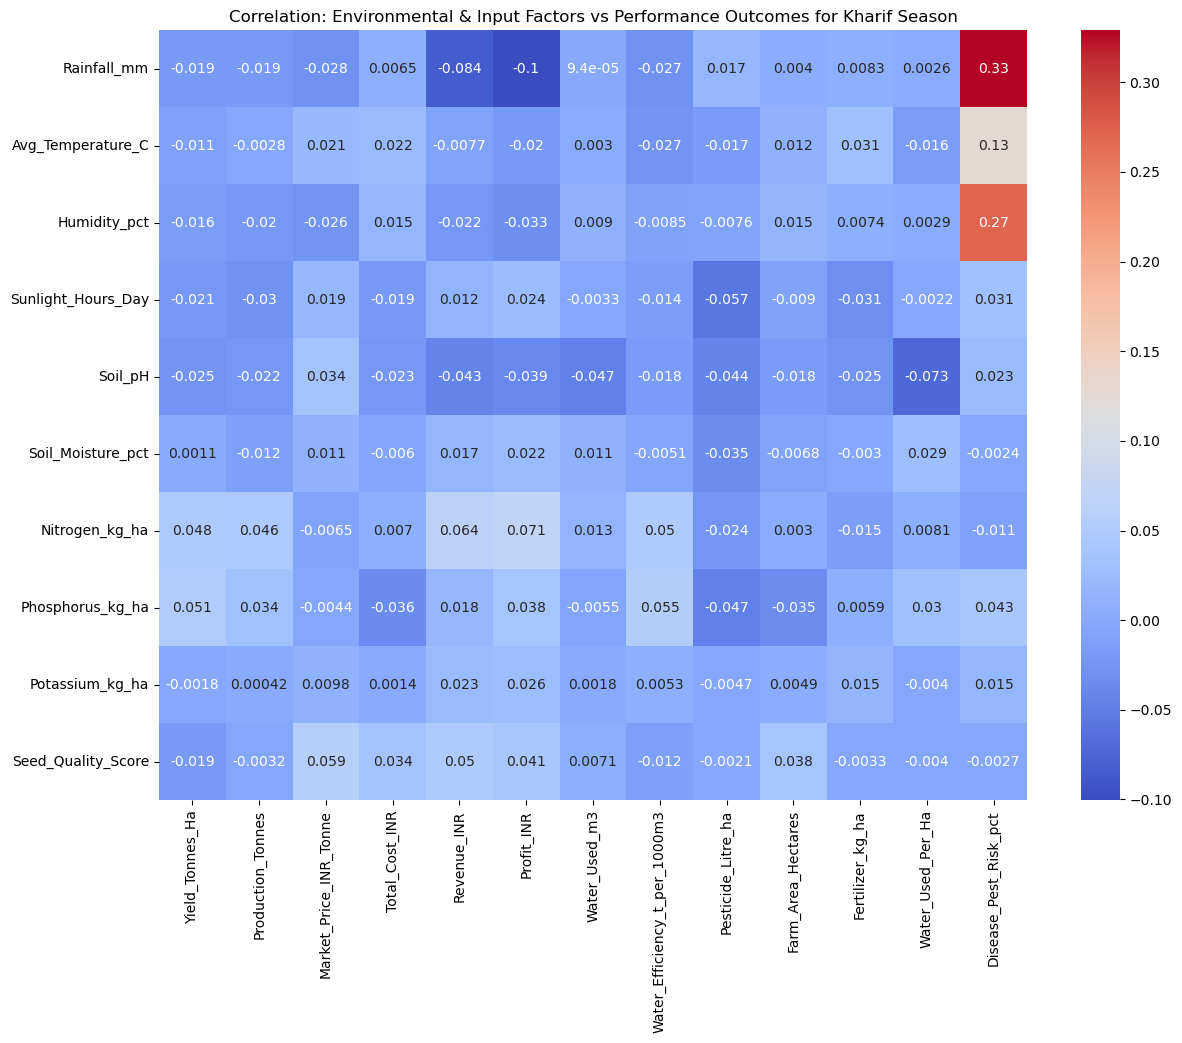

In [51]:
kharif_df = agri_df.where(agri_df['Season'] == 'Kharif')
corr_matrix = kharif_df[input_classes + output_classes].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix.loc[input_classes, output_classes], annot=True, cmap='coolwarm')
plt.title('Correlation: Environmental & Input Factors vs Performance Outcomes for Kharif Season')
plt.show()

### 3. HeatMap for Rabi

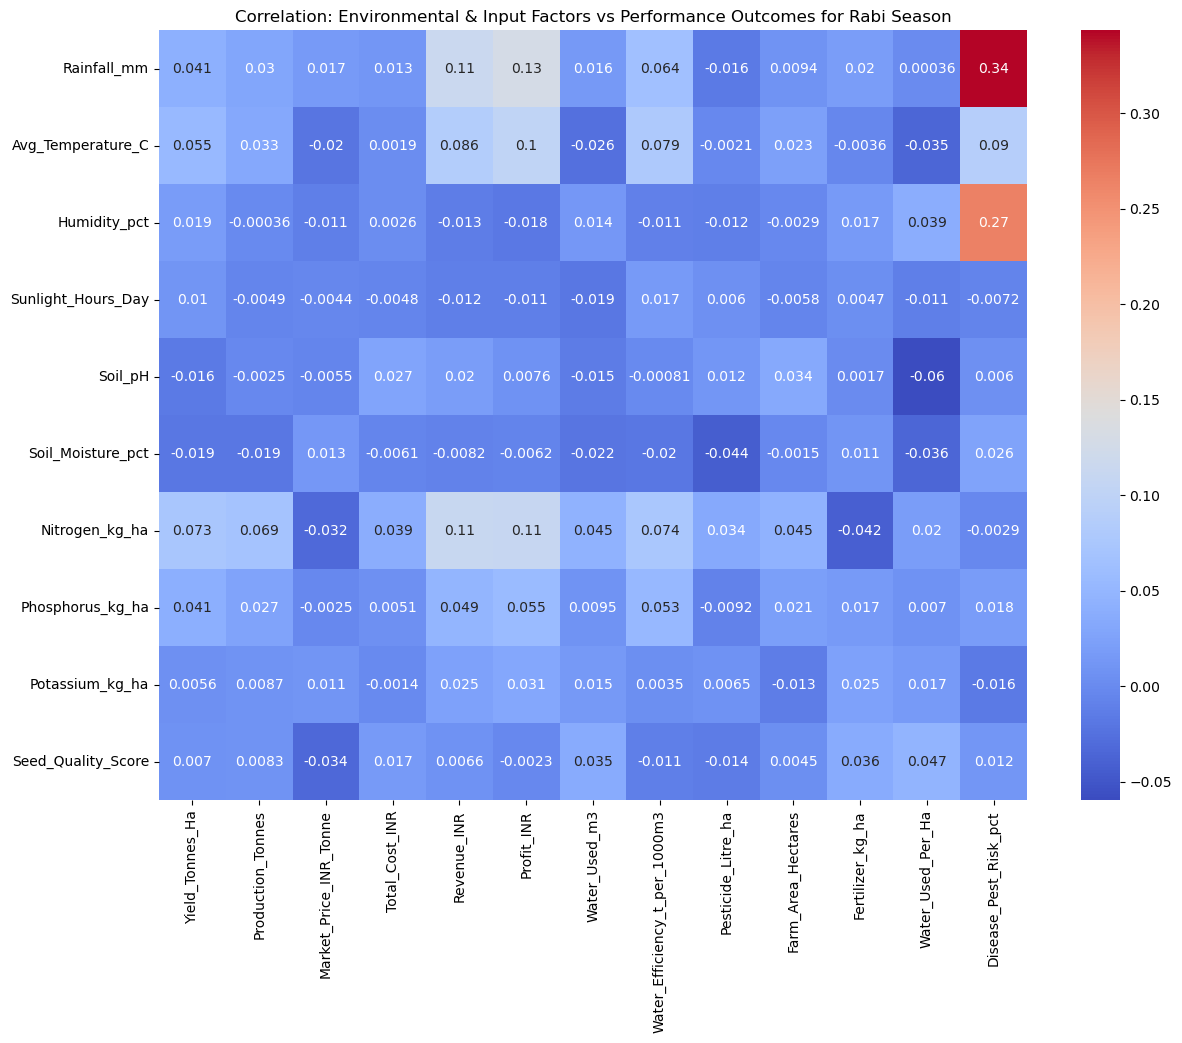

In [52]:
rabi_df = agri_df.where(agri_df['Season'] == 'Rabi')
corr_matrix = rabi_df[input_classes + output_classes].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix.loc[input_classes, output_classes], annot=True, cmap='coolwarm')
plt.title('Correlation: Environmental & Input Factors vs Performance Outcomes for Rabi Season')
plt.show()

### 3. HeatMap for Rabi

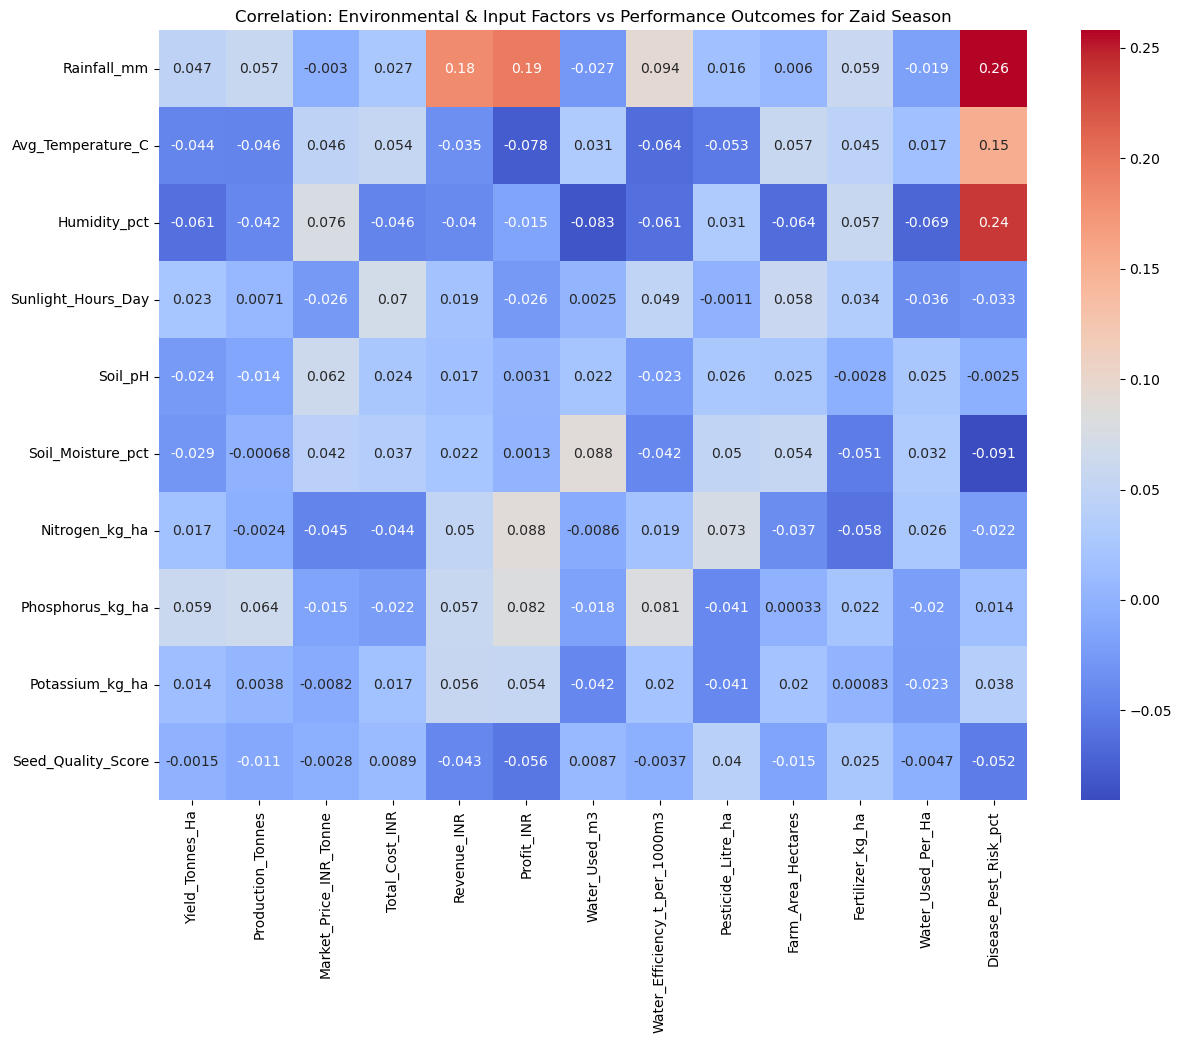

In [53]:
zaid_df = agri_df.where(agri_df['Season'] == 'Zaid')
corr_matrix = zaid_df[input_classes + output_classes].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix.loc[input_classes, output_classes], annot=True, cmap='coolwarm')
plt.title('Correlation: Environmental & Input Factors vs Performance Outcomes for Zaid Season')
plt.show()

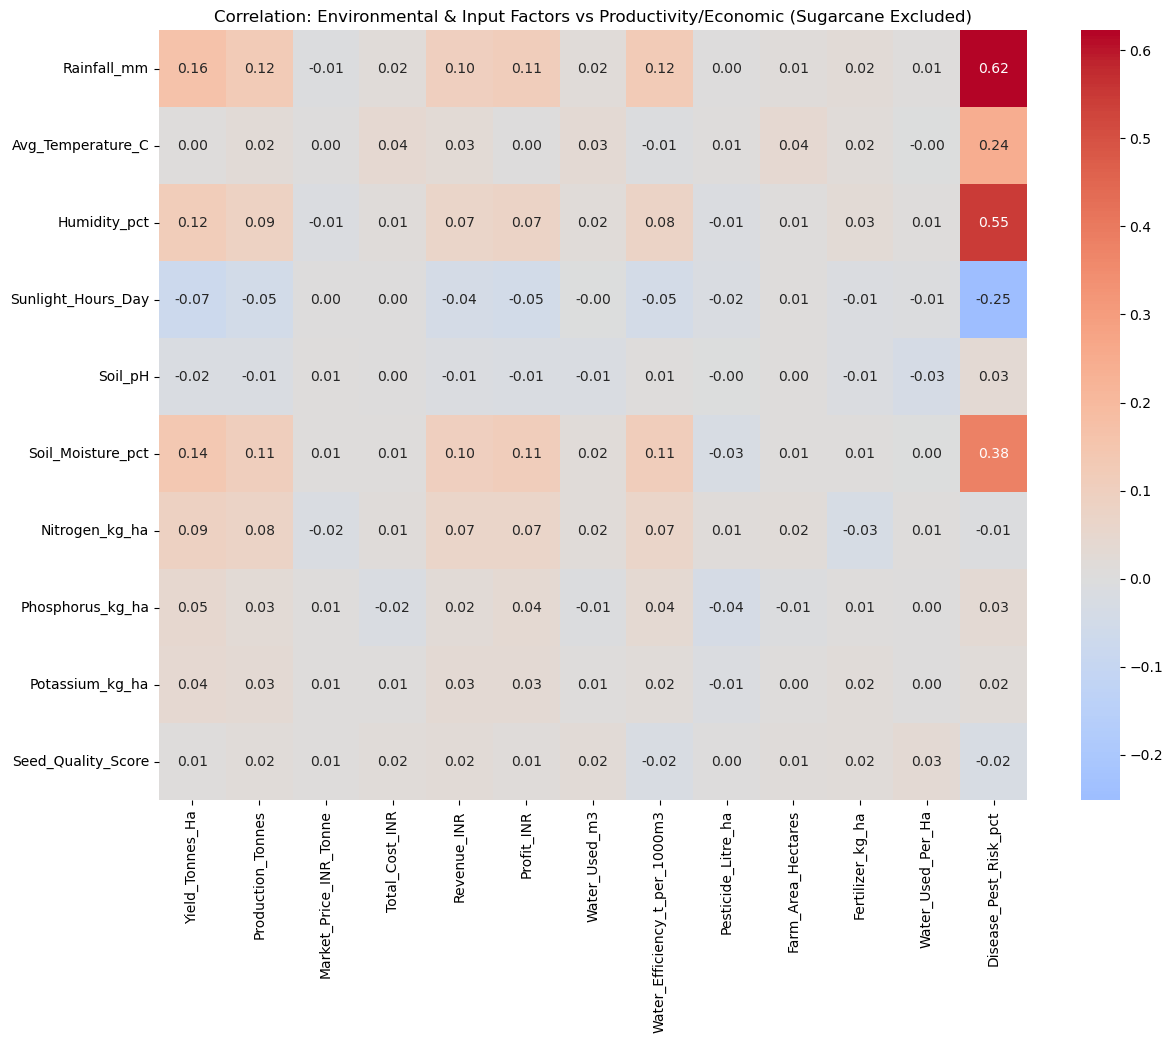

In [54]:
corr_no_sugar = df_no_sugar[input_classes + output_classes].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_no_sugar.loc[input_classes, output_classes], annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation: Environmental & Input Factors vs Productivity/Economic (Sugarcane Excluded)')
plt.show()

Above heaatmaps ones with sugarcane included show that the rain fall has not much of effect on the overall yeild but after removing sugarcane from the picture is evident that other crops need higher rainfall for higher yield.